# Homework 3: Time Series Feature Extraction
**Name:** Vishnu Gamini  
**GitHub Username:** vishnugamini  
**USC ID:** 6350365744  
**Course:** DSCI 552

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.float_format", lambda value: f"{value:.5f}")

project_root = Path("..") if Path("../data/AReM").is_dir() else Path(".")
data_dir = project_root / "data" / "AReM"
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
series_names = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
statistics = ["min", "max", "mean", "median", "std", "q1", "q3"]

## 1(a). AReM data and cleaning

Each recording contains six sensor series. The seven activity folders contain
88 recordings in total. The original files have three formatting irregularities:
`bending2/dataset4.csv` uses spaces, and `cycling/dataset9.csv` and
`cycling/dataset14.csv` have a trailing comma on their final data rows.

`sitting/dataset8.csv` contains 479 observed rows because the reading at
13,500 ms is absent. That single reading is linearly interpolated between
13,250 ms and 13,750 ms. Each cleaned recording therefore has 480 rows.
No observed sensor values are changed by these repairs.

In [2]:
def load_recording(path):
    rows = []
    whitespace_rows = 0
    trailing_comma_rows = 0
    for line_number, line in enumerate(path.read_text().splitlines(), start=1):
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        whitespace_rows += int("," not in line)
        trailing_comma_rows += int(line.endswith(","))
        fields = re.split(r"[,\s]+", line.rstrip(","))
        if len(fields) != 7:
            raise ValueError(f"{path.name}, line {line_number}: expected 7 values")
        rows.append([float(value) for value in fields])
    frame = pd.DataFrame(rows, columns=["time"] + series_names)
    assert np.isfinite(frame.to_numpy()).all()
    assert frame["time"].is_unique and frame["time"].is_monotonic_increasing
    expected_times = np.arange(0, 120000, 250)
    assert frame["time"].isin(expected_times).all()
    missing_times = sorted(set(expected_times) - set(frame["time"]))
    if missing_times:
        assert path.parent.name == "sitting" and path.name == "dataset8.csv"
        assert missing_times == [13500]
    cleaned = frame.set_index("time").reindex(expected_times)
    cleaned.index.name = "time"
    cleaned = cleaned.interpolate(method="index", limit_area="inside")
    assert cleaned.shape == (480, 6) and not cleaned.isna().any().any()
    report = {"activity": path.parent.name, "file": path.name,
              "observed_rows": len(frame), "cleaned_rows": len(cleaned),
              "space_delimited_rows": whitespace_rows,
              "trailing_comma_rows": trailing_comma_rows,
              "interpolated_rows": len(missing_times)}
    return cleaned, report

recordings = {}
audit_rows = []
manifest_rows = []
for activity in activities:
    paths = sorted((data_dir / activity).glob("dataset*.csv"),
                   key=lambda path: int(path.stem.removeprefix("dataset")))
    for path in paths:
        dataset_id = int(path.stem.removeprefix("dataset"))
        instance = len(recordings) + 1
        recordings[instance], report = load_recording(path)
        audit_rows.append(report)
        manifest_rows.append({"instance": instance, "activity": activity,
                              "dataset": dataset_id})
manifest = pd.DataFrame(manifest_rows).set_index("instance")
cleaning_report = pd.DataFrame(audit_rows)
assert len(recordings) == 88
assert manifest.groupby("activity", sort=False).size().tolist() == [7, 6, 15, 15, 15, 15, 15]
display(manifest.groupby("activity", sort=False).size().rename("recordings").to_frame())
affected = cleaning_report.loc[
    cleaning_report[["space_delimited_rows", "trailing_comma_rows", "interpolated_rows"]].sum(axis=1) > 0
]
display(affected.reset_index(drop=True))
cleaning_report.to_csv(output_dir / "cleaning_report.csv", index=False)

,recordings
activity,
bending1,7
bending2,6
cycling,15
lying,15
sitting,15
standing,15
walking,15


,activity,file,observed_rows,cleaned_rows,space_delimited_rows,trailing_comma_rows,interpolated_rows
0,bending2,dataset4.csv,480,480,480,0,0
1,cycling,dataset9.csv,480,480,0,1,0
2,cycling,dataset14.csv,480,480,0,1,0
3,sitting,dataset8.csv,479,480,0,0,1


## 1(b). Training and test recordings

Datasets 1 and 2 from each bending folder are reserved for testing. For all
other activities, datasets 1, 2, and 3 are reserved for testing. This gives
69 training recordings and 19 test recordings.

In [3]:
test_limit = manifest["activity"].map(lambda activity: 2 if activity.startswith("bending") else 3)
manifest["split"] = np.where(manifest["dataset"] <= test_limit, "test", "train")
split_counts = pd.crosstab(manifest["activity"], manifest["split"]).reindex(activities)
split_counts = split_counts[["train", "test"]]
split_counts.loc["Total"] = split_counts.sum()
display(split_counts)
assert manifest["split"].value_counts().to_dict() == {"train": 69, "test": 19}

split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3
Total,69,19


## 1(c)(i). Common time-domain features

Time-domain features summarize sensor values or their evolution over time:

| Type | Common features | Information captured |
|---|---|---|
| Location and extremes | Mean, median, minimum, maximum, quartiles | Typical levels and bounds |
| Spread | Standard deviation, variance, range, interquartile range, median absolute deviation | Variability and robust dispersion |
| Distribution shape | Skewness, kurtosis | Asymmetry and tail behavior |
| Magnitude | Root mean square, sum of squares (energy), mean absolute value | Signal magnitude |
| Temporal changes | Mean absolute successive difference, peak count, threshold or zero crossings | Changes and oscillations |
| Temporal dependence | Lagged autocorrelation, fitted trend slope | Persistence and direction of change |
| Complexity | Sample entropy, approximate entropy | Irregularity and repetition |

These are computed from observations in the time domain, rather than from a
Fourier spectrum. The [tsfresh feature catalog](https://tsfresh.readthedocs.io/en/latest/text/list_of_features.html)
documents examples of these feature families.

## 1(c)(ii). Extracting 42 features

Seven statistics are extracted separately from each of the six series:
minimum, maximum, mean, median, sample standard deviation, first quartile,
and third quartile. The sample standard deviation uses a denominator of
$480-1$. Quartiles use linear interpolation between adjacent ordered values.
Features remain in their original units.

The suffix identifies the series: 1 = `avg_rss12`, 2 = `var_rss12`,
3 = `avg_rss13`, 4 = `var_rss13`, 5 = `avg_rss23`, and 6 = `var_rss23`.
Thus, `q1_6` is the first quartile of `var_rss23`.

In [4]:
def extract_features(frame):
    result = {}
    for series_number, series_name in enumerate(series_names, start=1):
        values = frame[series_name].to_numpy()
        q1, q3 = np.quantile(values, [0.25, 0.75], method="linear")
        summaries = [np.min(values), np.max(values), np.mean(values),
                     np.median(values), np.std(values, ddof=1), q1, q3]
        result.update({f"{stat}_{series_number}": value
                       for stat, value in zip(statistics, summaries)})
    return result

features = pd.DataFrame.from_dict(
    {instance: extract_features(frame) for instance, frame in recordings.items()},
    orient="index"
)
features.index.name = "instance"
feature_names = [f"{stat}_{series_number}" for series_number in range(1, 7)
                 for stat in statistics]
features = features[feature_names]
assert features.shape == (88, 42) and np.isfinite(features.to_numpy()).all()
feature_data = manifest.join(features)
train_features = features.loc[manifest["split"] == "train"].copy()
test_features = features.loc[manifest["split"] == "test"].copy()
assert train_features.shape == (69, 42) and test_features.shape == (19, 42)
assert set(train_features.index).isdisjoint(test_features.index)
with pd.option_context("display.max_rows", 88, "display.max_columns", 42):
    display(features)
feature_data.to_csv(output_dir / "features.csv")
feature_data.loc[manifest["split"] == "train"].to_csv(output_dir / "train_features.csv")
feature_data.loc[manifest["split"] == "test"].to_csv(output_dir / "test_features.csv")

,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,min_2,max_2,mean_2,median_2,std_2,q1_2,q3_2,min_3,max_3,mean_3,median_3,std_3,q1_3,q3_3,min_4,max_4,mean_4,median_4,std_4,q1_4,q3_4,min_5,max_5,mean_5,median_5,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25000,45.00000,40.62479,40.50000,1.47697,39.25000,42.00000,0.00000,1.30000,0.35860,0.43000,0.32260,0.00000,0.50000,4.00000,29.50000,19.04094,19.25000,4.46295,16.00000,23.25000,0.00000,7.23000,0.83254,0.50000,0.96566,0.00000,1.12000,27.25000,38.25000,34.31129,35.00000,2.18845,33.00000,36.00000,0.00000,1.92000,0.57058,0.43000,0.58292,0.00000,1.30000
2,38.00000,45.67000,42.81281,42.50000,1.43555,42.00000,43.67000,0.00000,1.22000,0.37244,0.47000,0.28916,0.00000,0.50000,2.00000,29.50000,20.09698,21.00000,3.89374,19.00000,22.25000,0.00000,5.76000,0.87644,0.50000,1.04726,0.00000,1.14500,27.67000,38.50000,33.02458,33.00000,1.99525,32.00000,34.50000,0.00000,3.11000,0.57108,0.43000,0.60101,0.00000,1.30000
3,35.00000,47.40000,43.95450,44.33000,1.55884,43.00000,45.00000,0.00000,1.70000,0.42625,0.47000,0.33869,0.00000,0.50000,6.50000,29.75000,22.12235,23.00000,3.03094,19.75000,24.00000,0.00000,4.44000,0.49731,0.43000,0.55066,0.00000,0.83000,29.00000,38.50000,35.58846,36.00000,1.99960,35.36250,36.50000,0.00000,1.79000,0.49329,0.43000,0.51351,0.00000,0.94000
4,33.00000,47.75000,42.17981,43.50000,3.67067,39.15000,45.00000,0.00000,3.00000,0.69604,0.50000,0.63086,0.00000,1.12000,8.50000,30.00000,22.18362,23.00000,3.81047,20.50000,24.37250,0.00000,5.15000,0.98992,0.83000,0.95373,0.43000,1.30000,20.00000,38.67000,33.49392,35.00000,3.84945,30.45750,36.33000,0.00000,2.18000,0.61352,0.50000,0.52432,0.00000,1.00000
5,33.00000,45.75000,41.67806,41.75000,2.24349,41.33000,42.75000,0.00000,2.83000,0.53598,0.50000,0.40547,0.43000,0.71000,3.00000,28.25000,19.00656,19.12500,4.08711,16.50000,22.06250,0.00000,6.42000,0.84188,0.50000,0.92880,0.43000,1.12000,23.67000,37.50000,29.85708,30.00000,2.41103,28.45750,31.25000,0.00000,1.79000,0.38329,0.43000,0.38916,0.00000,0.50000
6,37.00000,48.00000,43.45496,43.25000,1.38610,42.50000,45.00000,0.00000,1.58000,0.37808,0.47000,0.31557,0.00000,0.50000,5.75000,27.00000,15.79333,15.00000,3.84764,13.00000,18.27000,0.00000,10.03000,0.84935,0.50000,0.99576,0.43000,1.12000,8.00000,33.50000,23.03479,23.50000,2.48886,22.25000,24.00000,0.00000,5.26000,0.67965,0.50000,0.62253,0.43000,0.87000
7,36.25000,48.00000,43.96912,44.50000,1.61836,43.31000,44.67000,0.00000,1.50000,0.41312,0.47000,0.26311,0.43000,0.50000,1.50000,26.33000,15.86802,16.25000,3.74242,14.25000,18.00000,0.00000,5.17000,0.66635,0.47000,0.78898,0.00000,0.94000,11.33000,30.75000,22.10375,21.67000,3.31830,20.50000,23.75000,0.00000,2.96000,0.55531,0.49000,0.48783,0.00000,0.83000
8,12.75000,51.00000,24.56296,24.25000,3.73751,23.18750,26.50000,0.00000,6.87000,0.59083,0.43000,0.83741,0.00000,0.71000,0.00000,25.33000,19.12133,20.25000,4.29961,18.00000,22.00000,0.00000,6.76000,0.73677,0.47000,0.92705,0.00000,0.87000,10.67000,30.00000,23.49304,23.75000,3.69379,20.50000,27.00000,0.00000,4.97000,0.70019,0.50000,0.69372,0.43000,0.87000
9,0.00000,42.75000,27.46460,28.00000,3.58358,25.50000,30.00000,0.00000,7.76000,0.44971,0.43000,0.76720,0.00000,0.50000,7.50000,35.00000,20.84254,20.75000,3.82627,18.00000,22.50000,0.00000,5.76000,0.77992,0.50000,0.90444,0.00000,0.94000,0.00000,33.00000,17.61794,18.00000,5.05364,15.00000,20.75000,0.00000,6.76000,1.12213,0.83000,1.01234,0.47000,1.30000


## 1(c)(iii). Feature standard deviations and 90% bootstrap intervals

For each of the 42 feature columns, its standard deviation is estimated
**across the 88 recordings**, using the sample standard deviation with
denominator $88-1$. This differs from `std_1`, for example, which measures
variation across the 480 readings within one recording.

The bootstrap samples 88 recording rows with replacement 10,000 times
(random seed 42). Each replicate produces 42 standard deviations. The 5th
and 95th percentiles give a two-sided 90% percentile interval for each feature's
standard deviation. Resampling complete rows preserves the relationship
between features and avoids treating adjacent sensor readings as independent
recordings. The intervals describe the pooled activity mixture and assume
recordings are independent sampling units; they do not establish variability
across different people.

In [5]:
values = features.to_numpy()
n_recordings, n_features = values.shape
n_resamples = 10000
rng = np.random.default_rng(42)
bootstrap_std = np.empty((n_resamples, n_features))
batch_size = 250
for start in range(0, n_resamples, batch_size):
    stop = min(start + batch_size, n_resamples)
    indices = rng.integers(0, n_recordings, size=(stop - start, n_recordings))
    bootstrap_std[start:stop] = np.std(values[indices], axis=1, ddof=1)
lower, upper = np.quantile(bootstrap_std, [0.05, 0.95], axis=0, method="linear")
uncertainty = pd.DataFrame({"sample_std": np.std(values, axis=0, ddof=1),
                            "lower_90": lower, "upper_90": upper},
                           index=pd.Index(feature_names, name="feature"))
assert np.isfinite(uncertainty.to_numpy()).all()
assert (uncertainty["lower_90"] <= uncertainty["upper_90"]).all()
with pd.option_context("display.max_rows", 42):
    display(uncertainty)
uncertainty.to_csv(output_dir / "feature_uncertainty.csv")

,sample_std,lower_90,upper_90
feature,,,
min_1,9.56998,8.23600,10.77390
max_1,4.39436,3.33994,5.29314
mean_1,5.33570,4.70383,5.87581
median_1,5.44005,4.78398,6.00629
std_1,1.77216,1.56945,1.94950
q1_1,6.15359,5.57382,6.64861
q3_1,5.13892,4.33859,5.83400
min_2,0.00000,0.00000,0.00000
max_2,5.06273,4.63058,5.40110


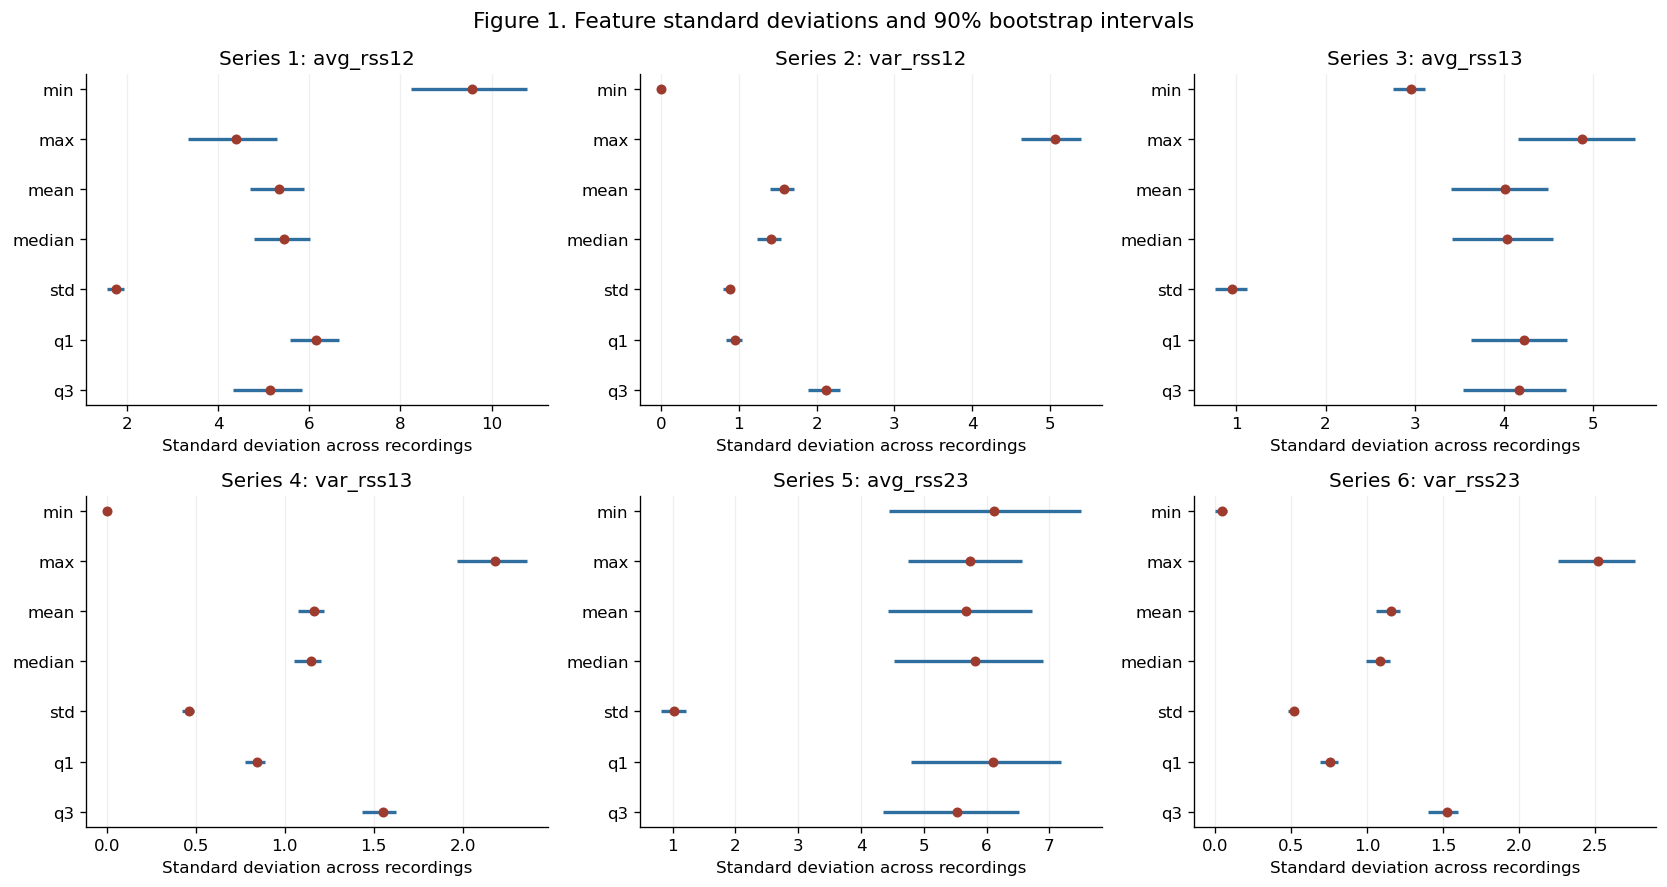

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for series_number, ax in enumerate(axes.flat, start=1):
    block = uncertainty.loc[[f"{stat}_{series_number}" for stat in statistics]]
    y = np.arange(len(statistics))
    ax.hlines(y, block["lower_90"], block["upper_90"], color="#2f6f9f", linewidth=2)
    ax.scatter(block["sample_std"], y, color="#9d3c2e", s=25, zorder=3)
    ax.set_yticks(y, statistics)
    ax.invert_yaxis()
    ax.set_title(f"Series {series_number}: {series_names[series_number - 1]}")
    ax.set_xlabel("Standard deviation across recordings")
    ax.grid(axis="x", alpha=0.2)
fig.suptitle("Figure 1. Feature standard deviations and 90% bootstrap intervals", fontsize=13)
fig.tight_layout()
plt.show()

In Figure 1, points show sample standard deviations and horizontal lines show the 90% intervals. `min_2` and `min_4` are zero in every recording, so both their standard deviations and their empirical bootstrap intervals are zero. These constant features cannot distinguish activities in this dataset.

## 1(c)(iv). Three selected time-domain statistics

The selected statistics are **mean, standard deviation, and maximum**.

- **Mean** summarizes the typical sensor level, which can vary with body position.
- **Standard deviation** summarizes movement-related variability within a recording.
- **Maximum** captures the upper signal level and brief excursions that a mean can smooth out.

Together these cover location, spread, and an extreme. Median and quartiles
are useful robust alternatives, but often provide overlapping location
information. Maximum is more sensitive to unusual readings, so its value
should be checked when fitting a classifier. These three statistics produce
18 features across the six series. The selection is a judgment-based starting
point, not a claim that these features have the best predictive performance.
The summaries below use only the 69 training recordings.

,mean_1,std_1,max_1,mean_2,std_2,max_2,mean_3,std_3,max_3,mean_4,std_4,max_4,mean_5,std_5,max_5,mean_6,std_6,max_6
activity,,,,,,,,,,,,,,,,,,
bending1,43.45496,1.61836,47.75000,0.42625,0.33869,1.70000,19.00656,3.81047,28.25000,0.84188,0.92880,5.17000,29.85708,2.48886,37.50000,0.55531,0.51351,2.18000
bending2,30.99818,5.53397,46.50000,0.43631,0.65056,6.39000,14.26573,5.36262,28.29000,0.80054,0.95817,6.36000,18.25349,5.43917,34.87500,1.10273,0.95616,6.56500
cycling,36.75341,3.73464,44.33000,2.74667,1.90838,10.80000,16.32541,3.44258,26.87500,2.99510,1.72879,9.48000,16.67733,2.93429,24.50000,3.07149,1.73571,9.08500
lying,39.58701,0.86121,40.83500,0.39425,0.19520,1.00000,6.31432,3.33853,13.25000,0.45097,0.55218,3.78500,9.61745,4.07448,18.33500,0.63594,0.60840,4.06000
sitting,42.32143,1.70126,45.87500,0.43946,0.33917,1.99500,14.87657,4.80379,23.50000,0.70266,0.80116,5.56500,16.03571,4.57076,23.87500,0.85809,0.76433,5.85500
standing,43.45377,2.28993,47.41500,0.38477,0.36783,2.39000,15.67611,2.90272,21.25000,0.56688,0.69410,5.55000,13.24598,3.27538,20.87500,0.92236,0.73304,5.27500
walking,34.50971,4.74704,46.00000,4.37627,2.44826,13.70500,15.37128,2.91054,23.33000,3.20200,1.59693,9.09500,15.88302,3.12547,23.75000,3.31383,1.69167,9.19500


/var/folders/z8/_xxjmjrx1yb745vk2fmdd3800000gn/T/ipykernel_34562/4276380971.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxes = ax.boxplot(groups, labels=activities, patch_artist=True)
/var/folders/z8/_xxjmjrx1yb745vk2fmdd3800000gn/T/ipykernel_34562/4276380971.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxes = ax.boxplot(groups, labels=activities, patch_artist=True)
/var/folders/z8/_xxjmjrx1yb745vk2fmdd3800000gn/T/ipykernel_34562/4276380971.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxes = ax.boxplot(groups, labels=activities, patch_artist=True)


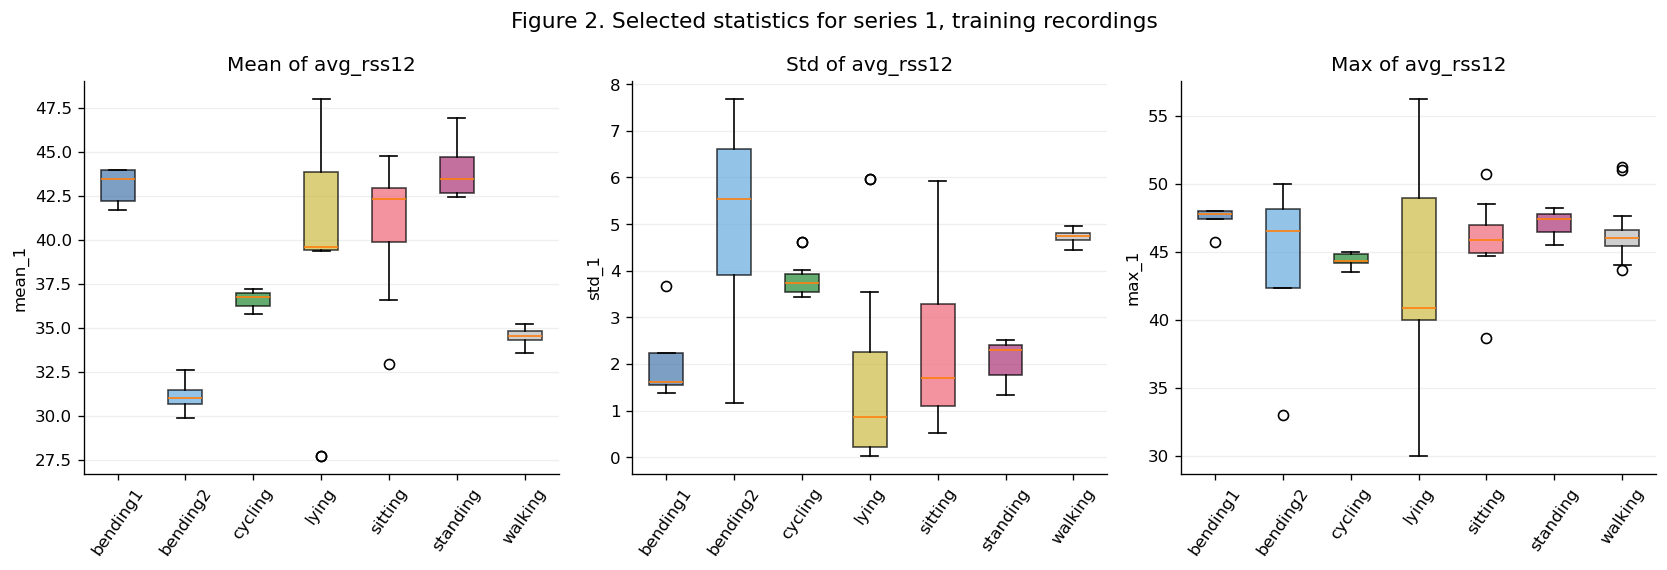

In [7]:
selected_statistics = ["mean", "std", "max"]
selected_features = [f"{stat}_{series_number}" for series_number in range(1, 7)
                     for stat in selected_statistics]
selected_train = train_features[selected_features]
training_summary = selected_train.join(manifest["activity"]).groupby("activity").median().reindex(activities)
with pd.option_context("display.max_columns", 18):
    display(training_summary)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
colors = ["#4477aa", "#66aadd", "#228833", "#ccbb44", "#ee6677", "#aa3377", "#bbbbbb"]
for stat, ax in zip(selected_statistics, axes):
    column = f"{stat}_1"
    groups = [selected_train.loc[manifest.loc[selected_train.index, "activity"] == activity, column]
              for activity in activities]
    boxes = ax.boxplot(groups, labels=activities, patch_artist=True)
    for patch, color in zip(boxes["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_title(f"{stat.capitalize()} of avg_rss12")
    ax.set_ylabel(column)
    ax.tick_params(axis="x", rotation=55)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Figure 2. Selected statistics for series 1, training recordings", fontsize=13)
fig.tight_layout()
plt.show()

Figure 2 illustrates complementary information in the selected statistics. The training median of `mean_1` is about 43.45 for both bending1 and standing, while the median of `std_1` differs (1.62 versus 2.29). Bending2 has a lower median mean (31.00) but a median maximum of 46.50, close to walking (46.00). No one of these statistics separates every activity on its own.

## 2. ISLR 3.7.4: Linear and cubic regression

There are 100 observations with one predictor and a quantitative response.
The fitted models are a line and a cubic polynomial:

$$\widehat{Y}_{L}=\widehat{\beta}_0+\widehat{\beta}_1X,$$
$$\widehat{Y}_{C}=\widehat{\beta}_0+\widehat{\beta}_1X+
\widehat{\beta}_2X^2+\widehat{\beta}_3X^3.$$

### (a) Training RSS when the true relationship is linear

**The cubic training RSS is no greater than the linear training RSS.**
Setting the cubic model's quadratic and cubic coefficients to zero reproduces
every line. Least squares minimizes RSS over a larger set of possible fits,
so it cannot have a worse training minimum:

$$\mathrm{RSS}_{C,\mathrm{train}}\leq\mathrm{RSS}_{L,\mathrm{train}}.$$

Even with a linear truth, the extra terms can fit random training noise and
reduce training RSS. Equality is possible, so a strict decrease is not guaranteed.

### (b) Test RSS when the true relationship is linear

**The linear model is generally expected to have lower test RSS.** It already
represents the true relationship. Estimating unnecessary quadratic and cubic
terms adds variance without improving the underlying approximation, which
can hurt predictions on new observations. This is an expectation, not a
guaranteed ordering for every realized training and test sample.

### (c) Training RSS when the true relationship is nonlinear

**The cubic training RSS is again no greater than the linear training RSS.**
The same model-containment argument applies regardless of the true
relationship. A cubic may improve the fit by capturing curvature, but the
training inequality itself follows from least-squares optimization, not from
assuming the true relationship is cubic.

### (d) Test RSS when the true relationship is nonlinear

**There is not enough information to determine which model has lower test RSS.**
If the curvature is substantial and well approximated by a cubic, the reduction
in bias may outweigh the additional estimation variance. If the relationship
is close to linear, the simpler model may generalize better. Noise level,
predictor distribution, and the form of the nonlinearity also matter; 100
observations alone do not determine the balance.

## References

1. Palumbo, F., Gallicchio, C., Pucci, R., and Micheli, A. (2016).
   *Activity Recognition system based on Multisensor data fusion (AReM)*.
   [UCI dataset](https://doi.org/10.24432/C5SS33), CC BY 4.0.
2. tsfresh documentation. [Overview of extracted features](https://tsfresh.readthedocs.io/en/latest/text/list_of_features.html).
3. SciPy documentation. [Bootstrap confidence intervals](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html).
4. NumPy documentation. [Standard deviation](https://numpy.org/doc/stable/reference/generated/numpy.std.html)
   and [quantiles](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html).
5. James, G., Witten, D., Hastie, T., and Tibshirani, R.
   *An Introduction to Statistical Learning*, first edition, seventh printing,
   Section 3.7, exercise 4, pp. 120-121.
   [Author-provided textbook](https://www.statlearning.com/s/ISLRSeventhPrinting.pdf).